<a href="https://colab.research.google.com/github/seanyi-creator/ba-305-project/blob/main/06_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Team A7 - Model comparison
**Question:** Can the details on a San Francisco building permit application predict whether the project will be abandoned rather than completed?

**Context:** Of the 62,148 resolved San Francisco building permits filed between 2000 and 2013, about 36% were never completed (expired, cancelled or withdrawn). Abandoned projects waste DBI review and inspection time. If the risk of abandonment can be estimated at filing, DBI can prioritize high-risk permits for early outreach.

**Purpose:** compare the tuned models from `02` (logistic regression), `03` (decision tree, random forest) and `04` (neural network) on the same data, to choose the model that best fits DBI's goal.

**Methodology:**
1. Refit each model with its tuned settings on the same training set (from `permits_data.py`).
2. Compare ranking ability (cross-validated and test ROC AUC), with bootstrap intervals for the differences.
3. Compare accuracy, recall and precision at the 0.5 cutoff and for the riskiest k% of permits.
4. Compare feature importance and performance on later permits (2011–2013).

**Target:**
* `y = 1` if the permit did not finish (expired, cancelled, withdrawn, disapproved, revoked or denied)
* `y = 0` if completed
* Recall and precision therefore refer to failing permits.

In [1]:
# --- setup ---
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             RocCurveDisplay)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
pd.set_option('display.max_columns', 50)

## Shared data (from `permits_data.py`)

In [2]:
# --- shared data: cleaning code lives in permits_data.py ---
# In Colab the file isn't there yet, so download it from the team GitHub repo first.
import os, urllib.request
if not os.path.exists('permits_data.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/seanyi-creator/ba-305-project/main/permits_data.py',
        'permits_data.py')

from permits_data import get_permit_data, make_cv, make_preprocessor, RANDOM_STATE

In [3]:
# --- load the shared split ---
X_train, X_test, y_train, y_test, groups_train, preprocessor = get_permit_data()
cv = make_cv()
print(f'Train: {len(X_train):,} permits · Test: {len(X_test):,} permits')
print(f'Did not finish: {y_train.mean():.1%} of train, {y_test.mean():.1%} of test')

Train: 49,676 permits · Test: 12,472 permits
Did not finish: 35.7% of train, 36.7% of test


## Tuned settings
| Model | Settings | Tuned in |
|---|---|---|
| Logistic regression | `C = 0.1`, `class_weight = 'balanced'` | `02`, Step 1 |
| Decision tree | `entropy`, `max_depth = 15`, `min_samples_leaf = 200` | `03`, Step 3 |
| Random forest | 200 trees, `entropy`, `max_features = 0.25`, `min_samples_leaf = 5` | `03`, Step 5 |
| Neural network | one hidden layer of 64, `alpha = 0.1`, learning rate 0.001, batches of 256, early stopping | `04`, Steps 5–6 |

In [4]:
# --- the four tuned models ---
COLORS = {'Logistic regression': '#3b6ea5', 'Decision tree': '#7a9a3a',
          'Random forest': '#c0581a', 'Neural network': '#7b4fa0'}

def make_models():
    return {
        'Logistic regression': LogisticRegression(max_iter=3000, C=0.1, class_weight='balanced'),
        'Decision tree': DecisionTreeClassifier(criterion='entropy', max_depth=15, min_samples_leaf=200,
                                                random_state=RANDOM_STATE),
        'Random forest': RandomForestClassifier(n_estimators=200, criterion='entropy', max_features=0.25,
                                                min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
        'Neural network': MLPClassifier(hidden_layer_sizes=(64,), alpha=0.1, learning_rate_init=0.001,
                                        batch_size=256, early_stopping=True, n_iter_no_change=10,
                                        max_iter=300, random_state=RANDOM_STATE),
    }

def pipe(model):
    return Pipeline([('prep', make_preprocessor()), ('model', model)])

## Step 1 — Model evaluation

In [5]:
# --- Step 1 — cross-validated AUC on the training set, then fit once and score on the test set ---
def scores(y_true, prob, pred):
    return {'test ROC AUC': roc_auc_score(y_true, prob),
            'accuracy': accuracy_score(y_true, pred),
            'recall': recall_score(y_true, pred, zero_division=0),
            'precision': precision_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred, zero_division=0),
            'share flagged': pred.mean()}

rows, fitted, probs = [], {}, {}
for name, strategy in [('Baseline: always "completed"', 'most_frequent'), ('Baseline: random guess', 'stratified')]:
    d = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append({'model': name, **scores(y_test, d.predict_proba(X_test)[:, 1], d.predict(X_test))})

for name, model in make_models().items():
    cv_auc = cross_validate(pipe(model), X_train, y_train, groups=groups_train, cv=cv,
                            scoring='roc_auc', n_jobs=-1)['test_score'].mean()
    t0 = time.time(); fitted[name] = pipe(model).fit(X_train, y_train); secs = time.time() - t0
    probs[name] = fitted[name].predict_proba(X_test)[:, 1]
    rows.append({'model': name, 'CV ROC AUC': cv_auc,
                 **scores(y_test, probs[name], (probs[name] >= 0.5).astype(int)), 'seconds to fit': secs})

results = pd.DataFrame(rows).set_index('model')
results = results[['CV ROC AUC', 'test ROC AUC', 'accuracy', 'recall', 'precision', 'F1', 'share flagged', 'seconds to fit']]
results.round(3)

,CV ROC AUC,test ROC AUC,accuracy,recall,precision,F1,share flagged,seconds to fit
model,,,,,,,,
"Baseline: always ""completed""",NaN,0.500,0.633,0.000,0.000,0.000,0.000,NaN
Baseline: random guess,NaN,0.498,0.538,0.349,0.365,0.357,0.351,NaN
Logistic regression,0.638,0.633,0.585,0.605,0.452,0.517,0.493,1.945
Decision tree,0.652,0.644,0.639,0.248,0.519,0.336,0.176,1.899
Random forest,0.701,0.698,0.669,0.335,0.588,0.427,0.209,50.283
Neural network,0.666,0.659,0.648,0.303,0.538,0.387,0.207,3.004


**Reading the table:**
- **Ranking (test AUC):** random forest **0.698** > neural network 0.659 > decision tree 0.644 > logistic regression 0.633 > baselines 0.50.
- **CV and test agree** for every model (within 0.01), so none of the tuning overfit the training set.
- **Accuracy** ranges from 58.5% to 66.9%, against 63.3% for always predicting "completed". Only the forest clearly beats it.
- **Logistic regression has the highest recall (60.5%)** because its `balanced` weighting flags 49% of permits, not because it ranks better. The other three flag about 18–21%.
- **Speed:** the forest is the slowest to fit (about 15–35 s depending on the machine). The others take seconds.

## Step 2 — ROC curves

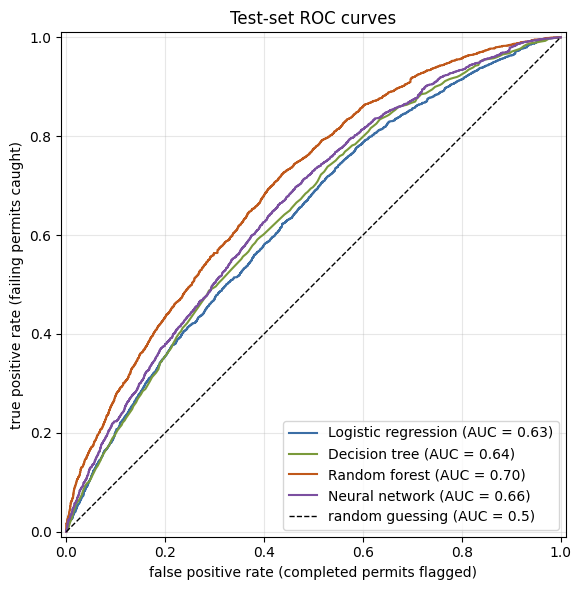

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, p in probs.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax, color=COLORS[name])
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='random guessing (AUC = 0.5)')
ax.set_xlabel('false positive rate (completed permits flagged)')
ax.set_ylabel('true positive rate (failing permits caught)')
ax.set_title('Test-set ROC curves'); ax.legend(loc='lower right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Reading the curves:** the random forest's curve sits above the others across almost the whole range, so it catches more failing permits at any false-alarm rate. The other three curves are close together.

## Step 3 — AUC differences

In [7]:
# --- Step 3 — bootstrap 95% intervals for every pair of models ---
names = list(probs)
pairs = [(a, b) for i, a in enumerate(names) for b in names[i + 1:]]
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
diffs = {f'{b} − {a}': [] for a, b in pairs}
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    auc = {m: roc_auc_score(yt[i], probs[m][i]) for m in names}
    for a, b in pairs:
        diffs[f'{b} − {a}'].append(auc[b] - auc[a])
boot = pd.DataFrame(diffs).quantile([0.025, 0.5, 0.975]).T.set_axis(['2.5%', 'difference', '97.5%'], axis=1)
boot['real difference?'] = np.where((boot['2.5%'] > 0) | (boot['97.5%'] < 0), 'yes', 'no')
boot.round(3)

,2.5%,difference,97.5%,real difference?
Decision tree − Logistic regression,0.002,0.011,0.020,yes
Random forest − Logistic regression,0.056,0.064,0.073,yes
Neural network − Logistic regression,0.020,0.026,0.032,yes
Random forest − Decision tree,0.045,0.053,0.061,yes
Neural network − Decision tree,0.007,0.014,0.022,yes
Neural network − Random forest,-0.046,-0.039,-0.031,yes


**Reading the intervals:** every interval excludes 0, so every gap between models is real rather than luck.
- The forest beats logistic regression by **0.064**, the tree by 0.053 and the network by 0.039.
- The network beats logistic regression by 0.026 and the tree by 0.014.
- The tree beats logistic regression by only 0.011 (interval 0.002 to 0.020).

*(The bootstrap resamples permits rather than project batches, so the intervals are slightly too narrow. The gaps are large enough that this doesn't change any conclusion.)*

## Step 4 — Recall and precision

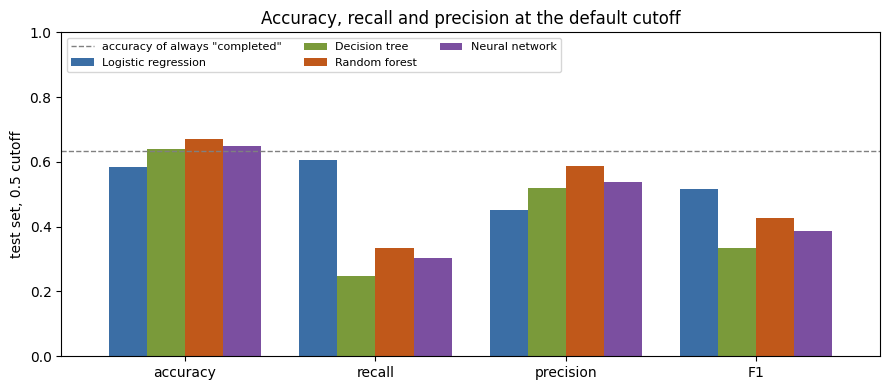

In [8]:
metrics = ['accuracy', 'recall', 'precision', 'F1']
model_rows = results.loc[list(probs), metrics]
ax = model_rows.T.plot.bar(figsize=(9, 4), color=[COLORS[m] for m in model_rows.index], rot=0, width=0.8)
ax.axhline(results.loc['Baseline: always "completed"', 'accuracy'], color='grey', ls='--', lw=1,
           label='accuracy of always "completed"')
ax.set_ylim(0, 1); ax.set_ylabel('test set, 0.5 cutoff'); ax.legend(ncol=3, fontsize=8, loc='upper left')
ax.set_title('Accuracy, recall and precision at the default cutoff')
plt.tight_layout(); plt.show()

**Reading the chart:** at the 0.5 cutoff the models trade recall for precision. Logistic regression catches the most failures (recall 61%) but only 45% of its flags are correct. The forest has the highest precision (59%) and accuracy (67%). Because the cutoff changes these numbers, the models are ranked on AUC and on the risk-ranking table below.

## Step 5 — Risk ranking

In [9]:
# --- Step 5 — if staff review the riskiest k% of permits, how many really fail? ---
rows = []
for k in [0.05, 0.10, 0.20, 0.30]:
    for name, p in probs.items():
        flag = (p >= np.quantile(p, 1 - k)).astype(int)
        rows.append({'review the riskiest': f'{k:.0%}', 'model': name,
                     'precision': precision_score(y_test, flag), 'recall': recall_score(y_test, flag)})
ranking = pd.DataFrame(rows)
print(f'Base rate (share of test permits that did not finish): {y_test.mean():.1%}')
(ranking.pivot(index='review the riskiest', columns='model', values=['precision', 'recall'])
        .loc[['5%', '10%', '20%', '30%']].round(3))

Base rate (share of test permits that did not finish): 36.7%


precision                                     \
model               Decision tree Logistic regression Neural network   
review the riskiest                                                    
5%                          0.587               0.558          0.630   
10%                         0.549               0.550          0.588   
20%                         0.516               0.522          0.539   
30%                         0.504               0.497          0.511   

                                         recall                      \
model               Random forest Decision tree Logistic regression   
review the riskiest                                                   
5%                          0.740         0.083               0.076   
10%                         0.650         0.151               0.150   
20%                         0.590         0.284               0.284   
30%                         0.552         0.412               0.406   

                                                  
model               Neural network Random forest  
review the riskiest                               
5%                           0.086         0.101  
10%                          0.160         0.177  
20%                          0.293         0.321  
30%                          0.418         0.451

**Reading the table:** with the same review list size, the forest's list is the most accurate at every size. Reviewing the riskiest 10%, **65%** of the forest's picks fail, against 59% for the network and 55% for the tree and logistic regression (base rate 37%). The forest also catches the most failures at every size (18% of all failures in the top 10%).

## Step 6 — Feature importance

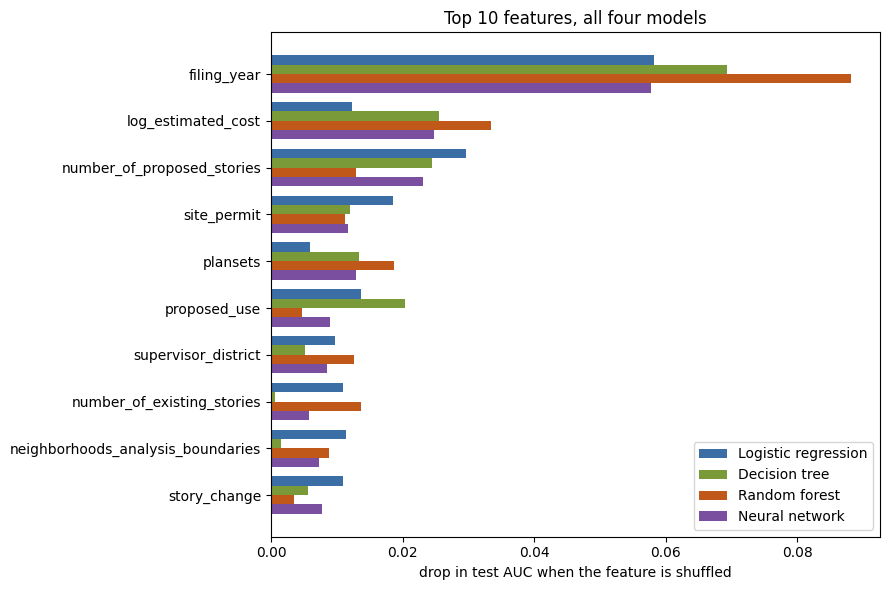

In [10]:
# --- Step 6 — permutation importance (drop in test AUC when a feature is shuffled) ---
imp = {}
for name, m in fitted.items():
    r = permutation_importance(m, X_test, y_test, scoring='roc_auc', n_repeats=5,
                               random_state=RANDOM_STATE, n_jobs=-1)
    imp[name] = pd.Series(r.importances_mean, index=X_test.columns)
imp = pd.DataFrame(imp)
imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]

top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
y, h = np.arange(len(top)), 0.2
for j, name in enumerate(imp.columns):
    ax.barh(y + (1.5 - j) * h, top[name], height=h, color=COLORS[name], label=name)
ax.set_yticks(y); ax.set_yticklabels(top.index)
ax.set_xlabel('drop in test AUC when the feature is shuffled'); ax.legend()
ax.set_title('Top 10 features, all four models')
plt.tight_layout(); plt.show()

In [11]:
# rank of each feature within each model (1 = most important)
imp.rank(ascending=False).astype(int).head(10)

,Logistic regression,Decision tree,Random forest,Neural network
filing_year,1,1,1,1
log_estimated_cost,5,2,2,2
number_of_proposed_stories,2,3,5,3
site_permit,3,6,7,5
plansets,12,5,3,4
proposed_use,4,4,11,6
supervisor_district,9,11,6,7
number_of_existing_stories,8,21,4,12
neighborhoods_analysis_boundaries,6,17,9,10
story_change,7,10,16,8


**Reading the chart:** all four models put **`filing_year` first**, and estimated cost and proposed stories are in the top five for almost all of them. Site permits, plan sets and building use come next. Four models built in different ways agreeing on what matters makes the finding more trustworthy, but it also means every model leans on filing year.

## Step 7 — Validation over time

In [12]:
# --- Step 7 — train on 2000–2010, test on 2011–2013 ---
X_all, y_all = pd.concat([X_train, X_test]), pd.concat([y_train, y_test])
early = (X_all['filing_year'] <= 2010).to_numpy()
print(f'Train 2000–2010: {early.sum():,} permits, {y_all[early].mean():.1%} did not finish')
print(f'Test 2011–2013: {(~early).sum():,} permits, {y_all[~early].mean():.1%} did not finish')

rows = []
for name, model in make_models().items():
    m = pipe(model).fit(X_all[early], y_all[early])
    rows.append({'model': name, 'test AUC, random split (Step 1)': results.loc[name, 'test ROC AUC'],
                 'test AUC, 2011–2013 permits': roc_auc_score(y_all[~early], m.predict_proba(X_all[~early])[:, 1])})
temporal = pd.DataFrame(rows).set_index('model')
temporal['change'] = temporal.iloc[:, 1] - temporal.iloc[:, 0]
temporal.round(3)

Train 2000–2010: 56,462 permits, 37.6% did not finish
Test 2011–2013: 5,686 permits, 19.6% did not finish


,"test AUC, random split (Step 1)","test AUC, 2011–2013 permits",change
model,,,
Logistic regression,0.633,0.601,-0.033
Decision tree,0.644,0.598,-0.047
Random forest,0.698,0.614,-0.084
Neural network,0.659,0.614,-0.045


**Reading the table:** every model loses accuracy on permits filed after its training years, and the failure rate itself falls from 37.6% to 19.6%. The forest drops the most (0.698 → 0.614) and ties with the network at 0.614. Logistic regression and the tree fall to about 0.60. On later permits the models are much closer than on the random split, so any deployment would need retraining on recent permits.

## Step 8 — Conclusions

In [13]:
summary = results.loc[list(probs), ['test ROC AUC', 'accuracy', 'recall', 'precision', 'seconds to fit']].copy()
summary['AUC, 2011–2013'] = temporal['test AUC, 2011–2013 permits']
summary['precision, riskiest 10%'] = ranking[ranking['review the riskiest'] == '10%'].set_index('model')['precision']
summary['interpretable?'] = ['yes: odds ratios', 'yes: yes/no rules', 'partly: importance only', 'partly: importance only']
summary.round(3)

,test ROC AUC,accuracy,recall,precision,seconds to fit,"AUC, 2011–2013","precision, riskiest 10%",interpretable?
model,,,,,,,,
Logistic regression,0.633,0.585,0.605,0.452,1.945,0.601,0.550,yes: odds ratios
Decision tree,0.644,0.639,0.248,0.519,1.899,0.598,0.549,yes: yes/no rules
Random forest,0.698,0.669,0.335,0.588,50.283,0.614,0.650,partly: importance only
Neural network,0.659,0.648,0.303,0.538,3.004,0.614,0.588,partly: importance only


### Which model best fits DBI's goal?
**The random forest.** DBI needs a ranked list of the riskiest new permits, and the forest:
1. has the highest test AUC (0.698), with every gap to the other models confirmed by the bootstrap,
2. gives the most accurate review list (65% of its riskiest 10% fail, against a 37% base rate),
3. has the highest accuracy and precision at the default cutoff.

**Trade-offs:**
- **Interpretability:** the forest can only be explained through feature importance. Logistic regression (odds ratios) or the depth-3 tree in `03` can be used alongside it to explain why a permit is flagged.
- **Later permits:** on 2011–2013 permits the forest's lead shrinks to a tie with the network (0.614), so the model should be retrained on recent data before use.

### Why the forest wins on this data
The data is tabular: a few dozen mixed numeric and categorical columns, many of them one-hot. Trees split directly on thresholds such as "filed before 2003" and on single categories, and averaging 200 trees removes most of a single tree's instability. Logistic regression can only fit straight-line effects, and the network has to approximate sharp jumps with smooth curves.

### Answer to the question
Application details predict whether a permit will be abandoned **better than chance but modestly**: AUC about 0.70 on a random split and about 0.61 on later permits. That is enough to prioritize outreach to high-risk permits, but not to deny or delay permits.